# Contrast Limited Adaptive Histogram Equalization

In [2]:
import os
import os.path as ops

import math
import numpy as np
from matplotlib import pyplot as plt
import glob
import cv2

## CLAHE Function

In [3]:
 def clahe(img, v_w, h_w, color_depth=8, b=0.01):
    # img - The image to apply clahe on - from cv2.imread
    # v_w - The number of vertical windows (must divide heigth)
    # h_w - The number of horizontal windows (must divide width)
    # color_depth - The color depth of the image (by default 8bit)
    # b - Hyperparameter - Usually takes values within [0.01, 0.1]
    
    # Compute the histogram of a 1D image without normalization
    def get_hist(img):
        # img - The image to compute the histogram to - from cv2.imread
        hist = np.zeros(256)
        for i in range(img.shape[0]):
            for j in range(img.shape[1]):
                hist[img[i][j]] += 1
        return hist
    
    # Cumulative Distribution Function (CDF)
    def CDF(n, h, M, N):
        # • i, j are the coordinates of the image window;
        # • M is the number of pixels in the window;
        # • N is the number of grey levels (histogram bins); and
        # • h(i,j) is the histogram of the image window with coordinates (i, j).
        ret = (N - 1) * np.sum(h[0:n+1]) / M  # Optimization: formula rearranged (254.99999999999997 -> 255). Old formula divides N-1 with M
        return ret
    
    ## Compute clahe parameters:
    width = img.shape[1]
    heigth = img.shape[0]
    XX = width / h_w  # Window width
    if XX - int(XX) > 1E-4: # Check for integral part
        print("The number of horizontal windows must divide width!")
        return
    else:
        XX = int(XX)
    YY = heigth / v_w  # Window heigth
    if YY - int(YY) > 1E-4:
        print("The number of vertical windows must divide height!")
        return
    else:
        YY = int(YY)
    print(f"XX = {XX}, YY = {YY}")

    # Separate all the windows into a 4D vector
    # ws will contain all the windows sepparated in a matix of 4 dim (e.g. 80x80x9x16) for 80x80 windows which cover 9 rows and 16 cols
    ws = np.zeros((YY,XX,v_w,h_w))
    for vw in range(v_w):
        for hw in range(h_w):
            ws[:,:,vw,hw] = img[vw*YY:(vw+1)*YY, hw*XX:(hw+1)*XX]
    ws = ws.astype(np.uint8)
    
    # Compute the histograms for all the windows
    hist_size = np.power(2,color_depth)
    h = np.zeros((hist_size, v_w, h_w))
    # Get histograms of all the windows
    for vw in range(v_w):
        for hw in range(h_w):
            h[:,vw,hw] = get_hist(ws[:,:,vw,hw])
    
    plt.subplot(2,2,2)
    plt.plot(h[:,2,8])
    
    # Redistribute the excess in the histogram
    beta = int(b * XX * YY)
    print(f'beta = {beta}')

    for vw in range(v_w):
        for hw in range(h_w):
            v_h = h[:,vw,hw]# Only a vector out of the whole histogram
            # Get & Remove overabundant pixel number
            excess = 0
            for i in range(hist_size):
                if v_h[i] > beta:
                    excess += v_h[i] - beta
                    v_h[i] -= (v_h[i] - beta)

            # First redristibution of excess
            m = int(excess / hist_size)
            for i in range(hist_size):
                if (v_h[i] + m) < beta:
                    v_h[i] += m
                    excess -= m
                else:
                    if(v_h[i] != beta):
                        excess -= (beta - v_h[i])
                        v_h[i] = v_h[i] + (beta - v_h[i])
            # Second redistribution of excess
            while(excess > 0):
                for i in range(hist_size):
                    if (v_h[i] < beta) and (excess > 0):
                        v_h[i] += 1
                    excess -= 1
                    
    # Cumulative Distribution Function over all the histograms
    # - store all CDF values in vectors for each histogram.
    v_CDF = np.zeros((hist_size, v_w, h_w))
    for vw in range(v_w):
        for hw in range(h_w):
            for i in range(hist_size):
                v_CDF[i,vw,hw] = CDF(i, h[:,vw,hw], XX * YY, hist_size)
    
    # Bilinear interpolation - Recreate the image using CDFs and old image
    I_new = np.zeros((heigth, width))
    v_cen = v_w - 1
    h_cen = h_w - 1

    # Border Regions Coverage
    # Top Border
    vertical_coord = int(YY/2)
    for hc in range(0, h_cen): # Top Border
        h_offset = int((hc+1) * XX)

        LC = np.array([h_offset - XX/2, vertical_coord]).astype(np.uint32)
        RC = np.array([h_offset + XX/2, vertical_coord]).astype(np.uint32)

        LC_hist_horiz = int((h_offset - XX/2) / XX)
        RC_hist_horiz = int((h_offset + XX/2) / XX)
        LC_RC_hist_vert = 0
        for i in range(0, vertical_coord):
                for j in range(h_offset - int(XX/2), h_offset + int(XX/2)):
                    t = RC[0] - j
                    z = j - LC[0]

                    CDF_LC = v_CDF[img[i,j],LC_RC_hist_vert,LC_hist_horiz]
                    CDF_RC = v_CDF[img[i,j],LC_RC_hist_vert,RC_hist_horiz]
                    I_new[i,j] = (t/(z+t))*CDF_LC + (z/(z+t))*CDF_RC
    # Bottom Border
    vertical_coord = int(v_cen*YY + YY/2)
    for hc in range(0, h_cen):
        h_offset = int((hc+1) * XX)

        LC = np.array([h_offset - XX/2, vertical_coord]).astype(np.uint32)
        RC = np.array([h_offset + XX/2, vertical_coord]).astype(np.uint32)

        LC_hist_horiz = int((h_offset - XX/2) / XX)
        RC_hist_horiz = int((h_offset + XX/2) / XX)
        LC_RC_hist_vert = v_cen
        for i in range(vertical_coord, heigth):
                for j in range(h_offset - int(XX/2), h_offset + int(XX/2)):
                    t = RC[0] - j
                    z = j - LC[0]

                    CDF_LC = v_CDF[img[i,j],LC_RC_hist_vert,LC_hist_horiz]
                    CDF_RC = v_CDF[img[i,j],LC_RC_hist_vert,RC_hist_horiz]
                    I_new[i,j] = (t/(z+t))*CDF_LC + (z/(z+t))*CDF_RC

    # Left Border
    horizontal_coord = int(XX/2)
    for vc in range(0,v_cen): 
        v_offset = int((vc+1) * YY)

        UC = np.array([horizontal_coord, v_offset - YY/2]).astype(np.uint32)
        BC = np.array([horizontal_coord, v_offset + YY/2]).astype(np.uint32)

        UC_BC_horiz = 0
        UC_hist_vert = int((v_offset - YY/2) / YY)
        BC_hist_vert = int((v_offset + YY/2) / YY)

        for i in range(v_offset - int(YY/2), v_offset + int(YY/2)):
            for j in range(0, horizontal_coord):
                s = BC[1] - i
                w = i - UC[1]

                CDF_UC = v_CDF[img[i,j],UC_hist_vert,UC_BC_horiz]
                CDF_BC = v_CDF[img[i,j],BC_hist_vert,UC_BC_horiz]
                I_new[i,j] = (w/(w+s))*CDF_BC + (s/(w+s))*CDF_UC

    # Right Border
    horizontal_coord = int(h_cen * XX + XX/2)
    for vc in range(0,v_cen): 
        v_offset = int((vc+1) * YY)

        UC = np.array([horizontal_coord, v_offset - YY/2]).astype(np.uint32)
        BC = np.array([horizontal_coord, v_offset + YY/2]).astype(np.uint32)

        UC_BC_horiz = h_cen
        UC_hist_vert = int((v_offset - YY/2) / YY)
        BC_hist_vert = int((v_offset + YY/2) / YY)

        for i in range(v_offset - int(YY/2), v_offset + int(YY/2)):
            for j in range(horizontal_coord, width):
                s = BC[1] - i
                w = i - UC[1]

                CDF_UC = v_CDF[img[i,j],UC_hist_vert,UC_BC_horiz]
                CDF_BC = v_CDF[img[i,j],BC_hist_vert,UC_BC_horiz]
                I_new[i,j] = (w/(w+s))*CDF_BC + (s/(w+s))*CDF_UC
                
    # Top-Left Corner Coverage
    for i in range(0, int(YY/2)):
        for j in range(0, int(XX/2)):
            TL_Corner_CDF = v_CDF[img[i,j], 0, 0]
            I_new[i,j] = TL_Corner_CDF

    # Top-Right Corner Coverage
    horizontal_coord = int(h_cen * XX + XX/2)
    for i in range(0, int(YY/2)):
        for j in range(horizontal_coord, width):
            TR_Corner_CDF = v_CDF[img[i,j], 0, h_w-1]
            I_new[i,j] = TR_Corner_CDF

    # Bottom-Left Corner Coverage
    vertical_coord = int(v_cen*YY + YY/2)
    for i in range(vertical_coord, heigth):
        for j in range(0, int(XX/2)):
            BL_Corner_CDF = v_CDF[img[i,j], v_w-1, 0]
            I_new[i,j] = BL_Corner_CDF

    # Bottom-Right Corner Coverage
    vertical_coord = int(v_cen*YY + YY/2)
    for i in range(vertical_coord, heigth):
        for j in range(horizontal_coord, width):
            BR_Corner_CDF = v_CDF[img[i,j], v_w-1, h_w-1]
            I_new[i,j] = BR_Corner_CDF
    
    # Inner Regions Coverage
    for vc in range(v_cen):
        for hc in range(h_cen):
            h_offset = int((hc+1) * XX)
            v_offset = int((vc+1) * YY)
            # print(f"vc = {vc}", f"hc = {hc}", f"v_offset = {v_offset}", f"h_offset = {h_offset}", sep = '\t')

            UL = np.array([h_offset - XX/2, v_offset - YY/2]).astype(np.uint32)
            UR = np.array([h_offset + XX/2, v_offset - YY/2]).astype(np.uint32)
            BL = np.array([h_offset - XX/2, v_offset + YY/2]).astype(np.uint32)
            BR = np.array([h_offset + XX/2, v_offset + YY/2]).astype(np.uint32)
            # print(f"UL = {UL}", f"UR = {UR}", f"BL = {BL}", f"BR = {BR}", sep = '\t')

            UL_BL_hist_horiz = int((h_offset - XX/2) / XX)
            UR_BR_hist_horiz = int((h_offset + XX/2) / XX)
            UL_UR_hist_vert = int((v_offset - YY/2) / YY)
            BL_BR_hist_vert = int((v_offset + YY/2) / YY)
            # print(f"UL_BL_hist_horiz = {UL_BL_hist_horiz}", f"UR_BR_hist_horiz = {UR_BR_hist_horiz}", f"UL_UR_hist_vert = {UL_UR_hist_vert}", f"BL_BR_hist_vert = {BL_BR_hist_vert}", sep = '\t')

            for i in range(v_offset - int(YY/2), v_offset + int(YY/2)):
                for j in range(h_offset - int(XX/2), h_offset + int(XX/2)):
                    s = BR[1] - i
                    w = i - UR[1]
                    t = BR[0] - j
                    z = j - BL[0]

                    CDF_UL = v_CDF[img[i,j],UL_UR_hist_vert,UL_BL_hist_horiz]
                    CDF_UR = v_CDF[img[i,j],UL_UR_hist_vert,UR_BR_hist_horiz]
                    CDF_BL = v_CDF[img[i,j],BL_BR_hist_vert,UL_BL_hist_horiz]
                    CDF_BR = v_CDF[img[i,j],BL_BR_hist_vert,UR_BR_hist_horiz]

                    I_new[i,j] = (s/(s+w)*( (t/(z+t) * CDF_UL) + (z/(z+t) * CDF_UR))) + (w/(s+w)*( (t/(z+t) * CDF_BL) + (z/(z+t) * CDF_BR)))
                    # Document formula is wrong, \instead use above formula
                    # I_new[i,j] = (s/(s+w)*( (t/(z+t) * CDF_UL) + (z/(z+t) * CDF_BL))) + (w/(s+w)*( (t/(z+t) * CDF_UR) + (z/(z+t) * CDF_BR)))
    
    # plt.subplot(2,2,1)
    # plt.imshow(ws[:,:,3,13])
    # plt.subplot(2,2,2)
    # plt.plot(h[:,3,13])
    # plt.subplot(2,2,2)
    # plt.plot(v_CDF[:,3,13])
    # plt.subplot(2,2,3)
    # plt.imshow(I_new)
    
    return I_new

## CLAHE Testing

In [69]:
w_dir = os.getcwd()
src_dir = ops.join(w_dir, ops.join('TuLane','splits'))
training_fp = ops.join(ops.split(src_dir)[0], 'training')
img_fp = ops.join(training_fp, 'gt_image')
bin_fp = ops.join(training_fp, 'gt_binary_image')

img_path = glob.glob(ops.join(img_fp, "*.png"))

C:\Users\racov\LaneDetectionKeras\LaneNetApproach\TuLane\training\gt_image\3_1503.png


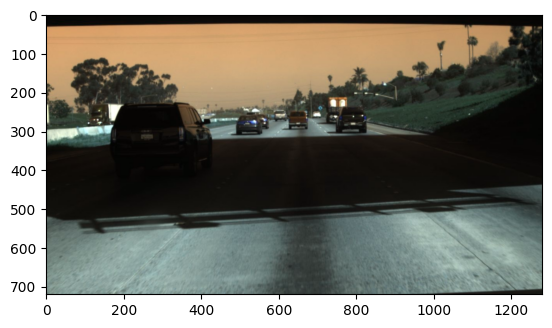

In [132]:
img = cv2.imread(img_path[1038])
print(img_path[1038])
# Convert the image to YCbCr color space
ycbcr_image = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)
plt.imshow(img)

XX = 80, YY = 80
beta = 64


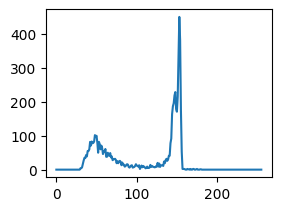

In [133]:
# Clahe is applied on the luminance of the RGB image
eq_lum = clahe(ycbcr_image[:,:,0], 9, 16)

Text(0.5, 1.0, 'CLAHE image')

<Figure size 640x480 with 0 Axes>

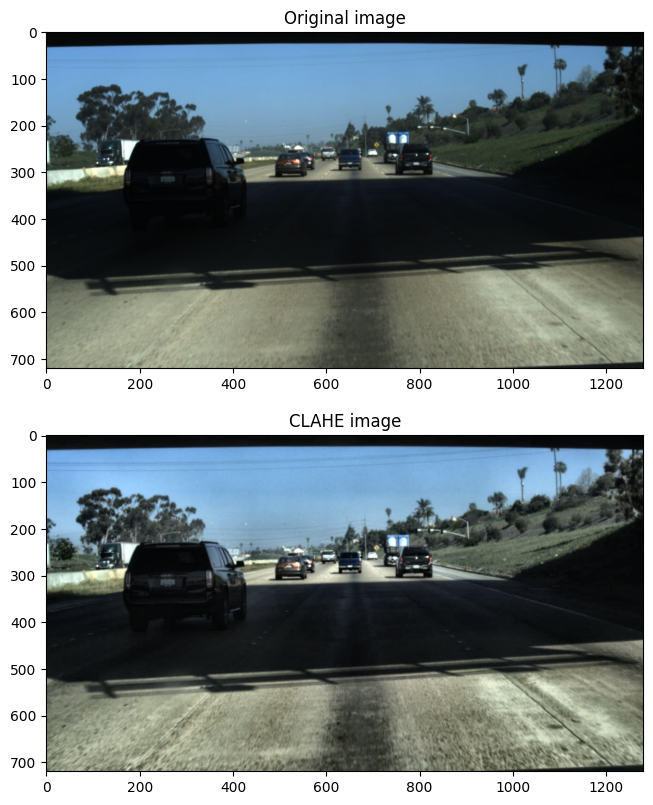

In [134]:
ycbcr_image[:,:,0] = eq_lum

f_img =  cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
eq_img = cv2.cvtColor(ycbcr_image, cv2.COLOR_YCrCb2RGB)


f = plt.figure()
window_factor = 2
plt.figure(figsize=(6.4*window_factor, 4.8*window_factor))

plt.subplot(2,1,1)
plt.imshow(f_img) 
plt.title(f"Original image")
plt.subplot(2,1,2)
plt.imshow(eq_img)
plt.title(f"CLAHE image")